In [1]:
import json
import sqlite3

import pandas as pd

conn = sqlite3.connect("../data/happiness_raw.db")
raw = pd.read_sql_query("SELECT * FROM raw_records", conn)

print(raw.shape)
print(raw.groupby("year").size())
raw.head()

(782, 7)
year
2015    158
2016    157
2017    155
2018    156
2019    156
dtype: int64


,record_id,year,source_file,kafka_partition,kafka_offset,kafka_ts,payload
0,2015-3,2015,2015.csv,0,1,1794769254624,"{""Country"": ""Denmark"", ""Region"": ""Western Euro..."
1,2015-5,2015,2015.csv,0,2,1794769254625,"{""Country"": ""Canada"", ""Region"": ""North America..."
2,2015-11,2015,2015.csv,0,3,1794769254625,"{""Country"": ""Israel"", ""Region"": ""Middle East a..."
3,2015-16,2015,2015.csv,0,4,1794769254625,"{""Country"": ""Brazil"", ""Region"": ""Latin America..."
4,2015-22,2015,2015.csv,0,5,1794769254625,"{""Country"": ""Oman"", ""Region"": ""Middle East and..."


In [2]:
ejemplo = raw.iloc[0]
print("Metadatos:", {k: v for k, v in ejemplo.items() if k != "payload"})
print("\nCampos originales:")
print(json.dumps(json.loads(ejemplo["payload"]), indent=2))

Metadatos: {'record_id': '2015-3', 'year': np.int64(2015), 'source_file': '2015.csv', 'kafka_partition': np.int64(0), 'kafka_offset': np.int64(1), 'kafka_ts': np.int64(1794769254624)}

Campos originales:
{
  "Country": "Denmark",
  "Region": "Western Europe",
  "Happiness Rank": 3,
  "Happiness Score": 7.527,
  "Standard Error": 0.03328,
  "Economy (GDP per Capita)": 1.32548,
  "Family": 1.36058,
  "Health (Life Expectancy)": 0.87464,
  "Freedom": 0.64938,
  "Trust (Government Corruption)": 0.48357,
  "Generosity": 0.34139,
  "Dystopia Residual": 2.49204
}


In [3]:
por_anio = {}
for year, g in raw.groupby("year"):
    por_anio[year] = pd.DataFrame([json.loads(p) for p in g["payload"]])

for year, df in por_anio.items():
    print(f"--- {year}: {df.shape}")
    print(df.dtypes.to_string())
    print("nulos:", df.isna().sum()[lambda s: s > 0].to_dict())
    print()

--- 2015: (158, 12)
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Standard Error                   float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity                       float64
Dystopia Residual                float64
nulos: {}

--- 2016: (157, 13)
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Lower Confidence Interval        float64
Upper Confidence Interval        float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Genero

In [4]:
cols = {y: set(df.columns) for y, df in por_anio.items()}
comunes = set.intersection(*cols.values())
print("Comunes a todos los años:", sorted(comunes))
for y, c in cols.items():
    print(y, "no comunes:", sorted(c - comunes))

presencia = (pd.DataFrame({y: pd.Series(1, index=list(c)) for y, c in cols.items()})
             .fillna(0).astype(int).sort_index())
presencia

Comunes a todos los años: ['Generosity']
2015 no comunes: ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Region', 'Standard Error', 'Trust (Government Corruption)']
2016 no comunes: ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Lower Confidence Interval', 'Region', 'Trust (Government Corruption)', 'Upper Confidence Interval']
2017 no comunes: ['Country', 'Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low']
2018 no comunes: ['Country or region', 'Freedom to make life choices', 'GDP per capita', 'Healthy life expectancy', 'Overall rank', 'Perceptions of corruption', 'Score', 'Social support']
2019 no comunes: ['Country or region', 'Freedom to ma

,2015,2016,2017,2018,2019
Country,1,1,1,0,0
Country or region,0,0,0,1,1
Dystopia Residual,1,1,0,0,0
Dystopia.Residual,0,0,1,0,0
Economy (GDP per Capita),1,1,0,0,0
Economy..GDP.per.Capita.,0,0,1,0,0
Family,1,1,1,0,0
Freedom,1,1,1,0,0
Freedom to make life choices,0,0,0,1,1
GDP per capita,0,0,0,1,1


In [5]:
resumen = pd.DataFrame({
    y: {"filas": df.shape[0], "columnas": df.shape[1],
        "filas_con_nulos": int(df.isna().any(axis=1).sum())}
    for y, df in por_anio.items()
}).T
print(resumen)

for y, df in por_anio.items():
    n = df.isna().sum()
    n = n[n > 0]
    if len(n):
        print(f"\n{y}: nulos por columna ->", n.to_dict())
        print(df[df.isna().any(axis=1)].to_string())

tipos = pd.DataFrame({y: df.dtypes.astype(str) for y, df in por_anio.items()})
print("\nColumnas cuyo tipo cambia entre años:")
print(tipos[tipos.nunique(axis=1) > 1])

      filas  columnas  filas_con_nulos
2015    158        12                0
2016    157        13                0
2017    155        12                0
2018    156         9                1
2019    156         9                0

2018: nulos por columna -> {'Perceptions of corruption': 1}
    Overall rank     Country or region  Score  GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
55            20  United Arab Emirates  6.774           2.096           0.776                     0.67                         0.284       0.186                        NaN

Columnas cuyo tipo cambia entre años:
Empty DataFrame
Columns: [2015, 2016, 2017, 2018, 2019]
Index: []


## Decisión de integración

Se apilan los cinco años en un único conjunto en formato largo (una fila por país y año),
con una columna `year`. Los nombres de columnas se unifican con una tabla de equivalencias.

**Columnas que se conservan:** country, year, score, gdp, social_support, life_expectancy,
freedom, corruption, generosity.

**Columnas que se descartan:**
- `Happiness Rank` / `Overall rank`: es el propio score expresado como posición.
- `Standard Error`, `Lower/Upper Confidence Interval`, `Whisker.high/low`: miden la
  incertidumbre del score y cada una existe en un solo año.
- `Dystopia Residual`: solo existe en 2015-2017.
- `Region`: solo existe en 2015-2016.

**Limitaciones:** (1) `Family` y `Social support` se tratan como la misma variable por su
nombre y posición, sin confirmación oficial; (2) un mismo país aparece varias veces, lo que
afecta la separación entrenamiento/prueba; (3) se pierde `Region` para 2017-2019.

In [6]:
EQUIVALENCIAS = {
    "country": ["Country", "Country or region"],
    "score": ["Happiness Score", "Happiness.Score", "Score"],
    "gdp": ["Economy (GDP per Capita)", "Economy..GDP.per.Capita.", "GDP per capita"],
    "social_support": ["Family", "Social support"],
    "life_expectancy": ["Health (Life Expectancy)", "Health..Life.Expectancy.",
                        "Healthy life expectancy"],
    "freedom": ["Freedom", "Freedom to make life choices"],
    "corruption": ["Trust (Government Corruption)", "Trust..Government.Corruption.",
                   "Perceptions of corruption"],
    "generosity": ["Generosity"],
}
RENOMBRAR = {viejo: nuevo for nuevo, viejos in EQUIVALENCIAS.items() for viejo in viejos}

partes = []
for year, df in por_anio.items():
    d = df.rename(columns=RENOMBRAR)[list(EQUIVALENCIAS)].copy()  # KeyError si falta alguna
    d.insert(1, "year", year)
    partes.append(d)

datos = pd.concat(partes, ignore_index=True)

print(datos.shape)
print(datos.groupby("year").size().to_dict())
print("duplicados país-año:", datos.duplicated(["country", "year"]).sum())
print(datos.dtypes)
print(datos.isna().sum().to_dict())
datos.head()

(782, 9)
{2015: 158, 2016: 157, 2017: 155, 2018: 156, 2019: 156}
duplicados país-año: 0
country                str
year                 int64
score              float64
gdp                float64
social_support     float64
life_expectancy    float64
freedom            float64
corruption         float64
generosity         float64
dtype: object
{'country': 0, 'year': 0, 'score': 0, 'gdp': 0, 'social_support': 0, 'life_expectancy': 0, 'freedom': 0, 'corruption': 1, 'generosity': 0}


,country,year,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
0,Denmark,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139
1,Canada,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811
2,Israel,2015,7.278,1.22857,1.22393,0.91387,0.41319,0.07785,0.33172
3,Brazil,2015,6.983,0.98124,1.23287,0.69702,0.49049,0.17521,0.14574
4,Oman,2015,6.853,1.36011,1.08182,0.76276,0.63274,0.32524,0.21542


In [7]:
from difflib import SequenceMatcher

anios_por_pais = datos.groupby("country")["year"].agg(["nunique", "min", "max"])
print("Países según en cuántos años aparecen:")
print(anios_por_pais["nunique"].value_counts().sort_index())
print("Total de países distintos:", datos["country"].nunique())

incompletos = anios_por_pais[anios_por_pais["nunique"] < 5].sort_values("min")
display(incompletos)

# Posibles nombres distintos de un mismo país: nunca coinciden en un año
# y se parecen entre sí
años = datos.groupby("country")["year"].apply(set)
nombres = list(incompletos.index)
print("\nPosibles variantes de nombre:")
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        if años[a].isdisjoint(años[b]):
            la, lb = a.lower(), b.lower()
            r = SequenceMatcher(None, la, lb).ratio()
            if r > 0.6 or la in lb or lb in la:
                print(f"{a!r} {sorted(años[a])}  <->  {b!r} {sorted(años[b])}  similitud={r:.2f}")

Países según en cuántos años aparecen:
nunique
1      9
2      4
3      4
4     12
5    141
Name: count, dtype: int64
Total de países distintos: 170


,nunique,min,max
country,,,
Angola,4,2015,2018
Central African Republic,4,2015,2019
Comoros,3,2015,2019
Djibouti,1,2015,2015
Hong Kong,4,2015,2019
Macedonia,4,2015,2018
Lesotho,4,2015,2019
Laos,4,2015,2019
North Cyprus,3,2015,2017



Posibles variantes de nombre:
'Hong Kong' [2015, 2016, 2018, 2019]  <->  'Hong Kong S.A.R., China' [2017]  similitud=0.56
'Macedonia' [2015, 2016, 2017, 2018]  <->  'North Macedonia' [2019]  similitud=0.75
'North Cyprus' [2015, 2016, 2017]  <->  'Northern Cyprus' [2018, 2019]  similitud=0.89
'Trinidad and Tobago' [2015, 2016, 2017]  <->  'Trinidad & Tobago' [2018, 2019]  similitud=0.89
'Taiwan' [2015, 2016, 2018, 2019]  <->  'Taiwan Province of China' [2017]  similitud=0.40
'Somaliland region' [2015]  <->  'Somaliland Region' [2016]  similitud=1.00


## Valores faltantes

Solo hay un nulo: `corruption` de United Arab Emirates en 2018. No se elimina la fila
(se perdería un registro con el resto de variables completas). Se imputará con la mediana
calculada **solo con los datos de entrenamiento**, dentro del pipeline del modelo, para que
la información del conjunto de prueba no influya en el entrenamiento.

In [8]:
CORRECCION_PAISES = {
    "Somaliland region": "Somaliland Region",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "North Cyprus": "Northern Cyprus",
    "Macedonia": "North Macedonia",
}

datos["country"] = datos["country"].str.strip().replace(CORRECCION_PAISES)

print("Países distintos:", datos["country"].nunique())
print("Duplicados país-año:", datos.duplicated(["country", "year"]).sum())
print(datos.groupby("country")["year"].nunique().value_counts().sort_index())

Países distintos: 164
Duplicados país-año: 0
year
1      4
2      3
3      2
4      9
5    146
Name: count, dtype: int64


## Inconsistencias en los nombres de países

Seis países aparecen con nombres distintos según el año (por ejemplo, `Macedonia` y
`North Macedonia`, o `Taiwan` y `Taiwan Province of China`). Sin corregirlo, cada variante
se contaría como un país distinto (170 en lugar de 164). Se unifican con un diccionario y
se comprueba que no aparezcan duplicados país-año.

Además, la cobertura no es constante: de los 164 países, 146 aparecen en los cinco años y
18 en menos (por ejemplo, Oman y Djibouti solo en 2015, Puerto Rico solo en 2016, Gambia
solo en 2019). No se imputan países ausentes: simplemente no aportan filas en esos años.

Estadísticas descriptivas y outliers

In [9]:
VARIABLES = ["score", "gdp", "social_support", "life_expectancy",
             "freedom", "corruption", "generosity"]
FEATURES = VARIABLES[1:]   # todas menos el objetivo

desc = datos[VARIABLES].describe().T
desc["nulos"] = datos[VARIABLES].isna().sum()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,nulos
score,782.0,5.379,1.127,2.693,4.510,5.322,6.190,7.769,0
gdp,782.0,0.916,0.407,0.000,0.606,0.982,1.236,2.096,0
social_support,782.0,1.078,0.330,0.000,0.869,1.125,1.327,1.644,0
life_expectancy,782.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141,0
freedom,782.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724,0
corruption,781.0,0.125,0.106,0.000,0.054,0.091,0.156,0.552,1
generosity,782.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838,0


In [10]:
datos.groupby("year")[VARIABLES].mean().round(3)

,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.143,0.237
2016,5.382,0.954,0.794,0.558,0.371,0.138,0.243
2017,5.354,0.985,1.189,0.551,0.409,0.123,0.247
2018,5.376,0.891,1.213,0.597,0.455,0.112,0.181
2019,5.407,0.905,1.209,0.725,0.393,0.111,0.185


In [11]:
print("Valores iguales a 0 por variable:")
print((datos[FEATURES] == 0).sum().to_string())


def contar_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()


print("\nOutliers por regla del IQR (1.5 × IQR):")
print(datos[VARIABLES].apply(contar_outliers).to_string())

Valores iguales a 0 por variable:
gdp                5
social_support     5
life_expectancy    5
freedom            5
corruption         6
generosity         5

Outliers por regla del IQR (1.5 × IQR):
score               0
gdp                 0
social_support     10
life_expectancy     0
freedom             0
corruption         67
generosity         17


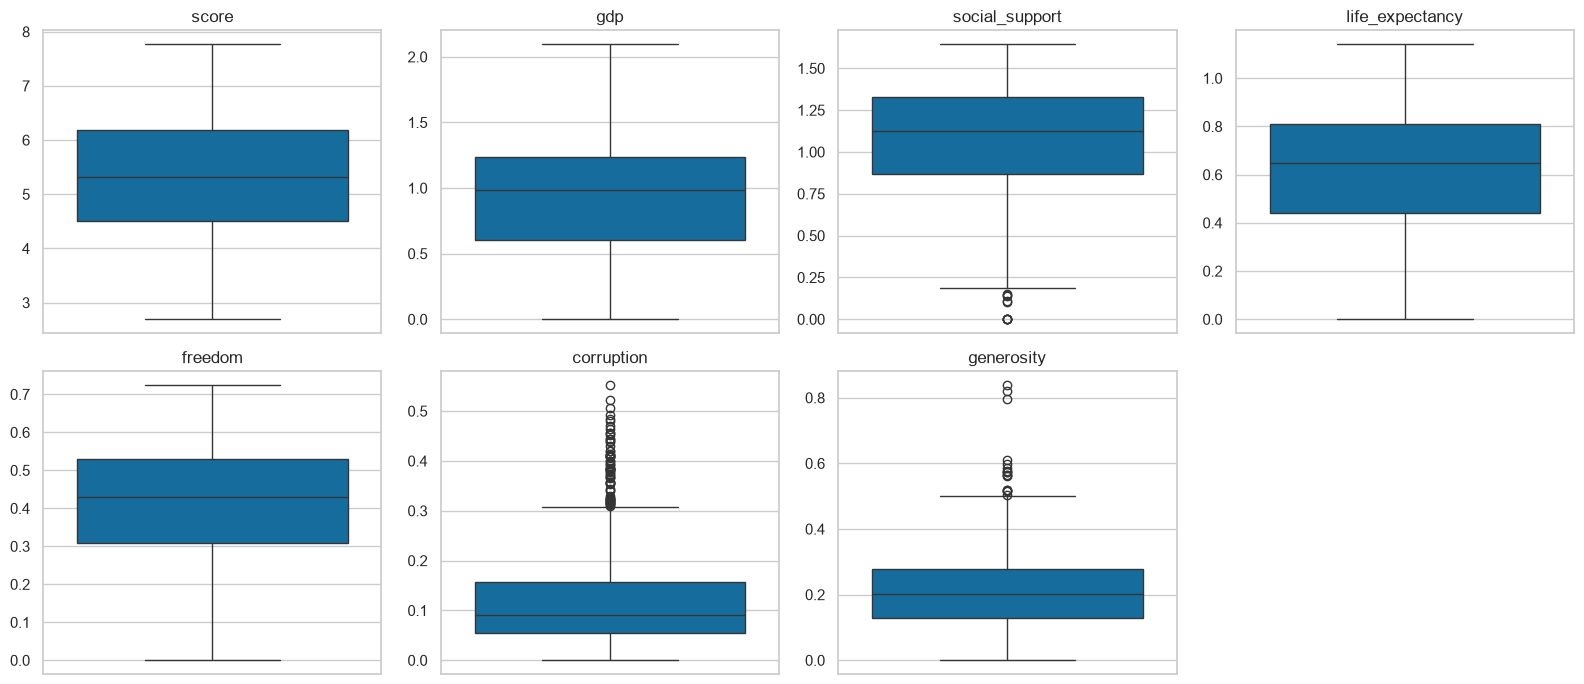

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), VARIABLES):
    sns.boxplot(y=datos[col], ax=ax, color="#0072B2")
    ax.set_title(col)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

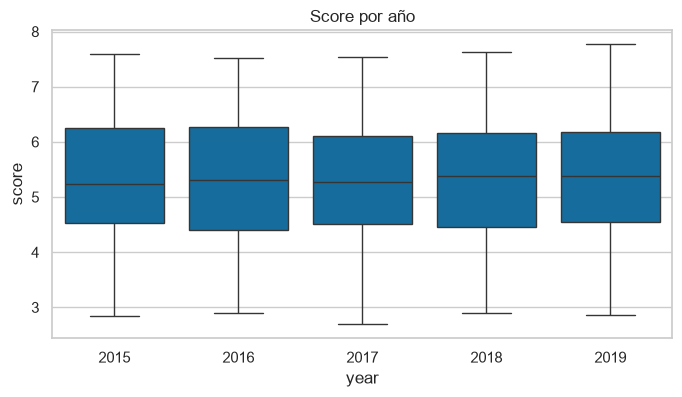

In [13]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=datos, x="year", y="score", color="#0072B2")
plt.title("Score por año")
plt.show()

## Diferencias entre años

El score medio es estable entre ediciones (5.35 a 5.41), pero varias variables cambian de
nivel: `social_support` baja a 0.79 en 2016 y sube a 1.19 en 2017; `life_expectancy` salta a
0.73 en 2019; `generosity` cae a 0.18 en 2018; `corruption` desciende de forma continua.
Hipótesis: cambios metodológicos entre ediciones (no verificada). Se tendrá en cuenta al
preparar las variables.

## Outliers

Por la regla del IQR hay 10 outliers en `social_support` (cola baja), 67 en `corruption` y
17 en `generosity` (cola alta). Son valores plausibles en variables sesgadas a la derecha,
no errores evidentes: se conservan, y se evaluará su efecto en el modelo.

In [14]:
con_ceros = datos[(datos[FEATURES] == 0).any(axis=1)]
print("Filas con algún cero:", len(con_ceros))
print("Ceros por fila:", (con_ceros[FEATURES] == 0).sum(axis=1).value_counts().to_dict())
con_ceros[["country", "year", "score"] + FEATURES]

Filas con algún cero: 30
Ceros por fila: {1: 29, 2: 1}


,country,year,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
16,Indonesia,2015,5.399,0.828270,1.087080,0.637930,0.466110,0.000000,0.515350
74,Greece,2015,4.857,1.154060,0.929330,0.882130,0.076990,0.013970,0.000000
80,Iraq,2015,4.677,0.985490,0.818890,0.602370,0.000000,0.137880,0.179220
83,Congo (Kinshasa),2015,4.517,0.000000,1.001200,0.098060,0.226050,0.076250,0.248340
141,Sierra Leone,2015,4.507,0.330240,0.955710,0.000000,0.408400,0.087860,0.214880
153,Central African Republic,2015,3.678,0.078500,0.000000,0.066990,0.488790,0.082890,0.238350
179,Somalia,2016,5.440,0.000000,0.336130,0.114660,0.567780,0.311800,0.272250
188,Sierra Leone,2016,4.635,0.364850,0.628000,0.000000,0.306850,0.081960,0.238970
198,Sudan,2016,4.139,0.630690,0.819280,0.297590,0.000000,0.100390,0.180770
288,Bosnia and Herzegovina,2016,5.163,0.933830,0.643670,0.707660,0.095110,0.000000,0.298890


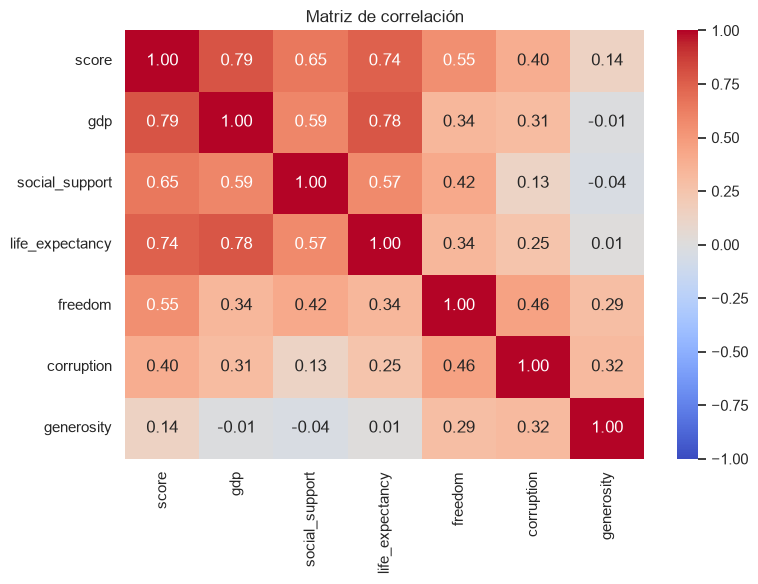

Pares de variables explicativas con |correlación| > 0.6:
[('gdp', 'life_expectancy', np.float64(0.78))]

Correlación con el score, por año:


,2015,2016,2017,2018,2019
gdp,0.781,0.790,0.812,0.802,0.794
social_support,0.741,0.739,0.753,0.746,0.777
life_expectancy,0.724,0.765,0.782,0.776,0.780
freedom,0.568,0.567,0.570,0.544,0.567
corruption,0.395,0.402,0.429,0.405,0.386
generosity,0.180,0.157,0.155,0.136,0.076


In [15]:
corr = datos[VARIABLES].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

print("Pares de variables explicativas con |correlación| > 0.6:")
print([(a, b, round(corr.loc[a, b], 2))
       for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
       if abs(corr.loc[a, b]) > 0.6])

print("\nCorrelación con el score, por año:")
pd.DataFrame({y: g[FEATURES].corrwith(g["score"])
              for y, g in datos.groupby("year")}).round(3)

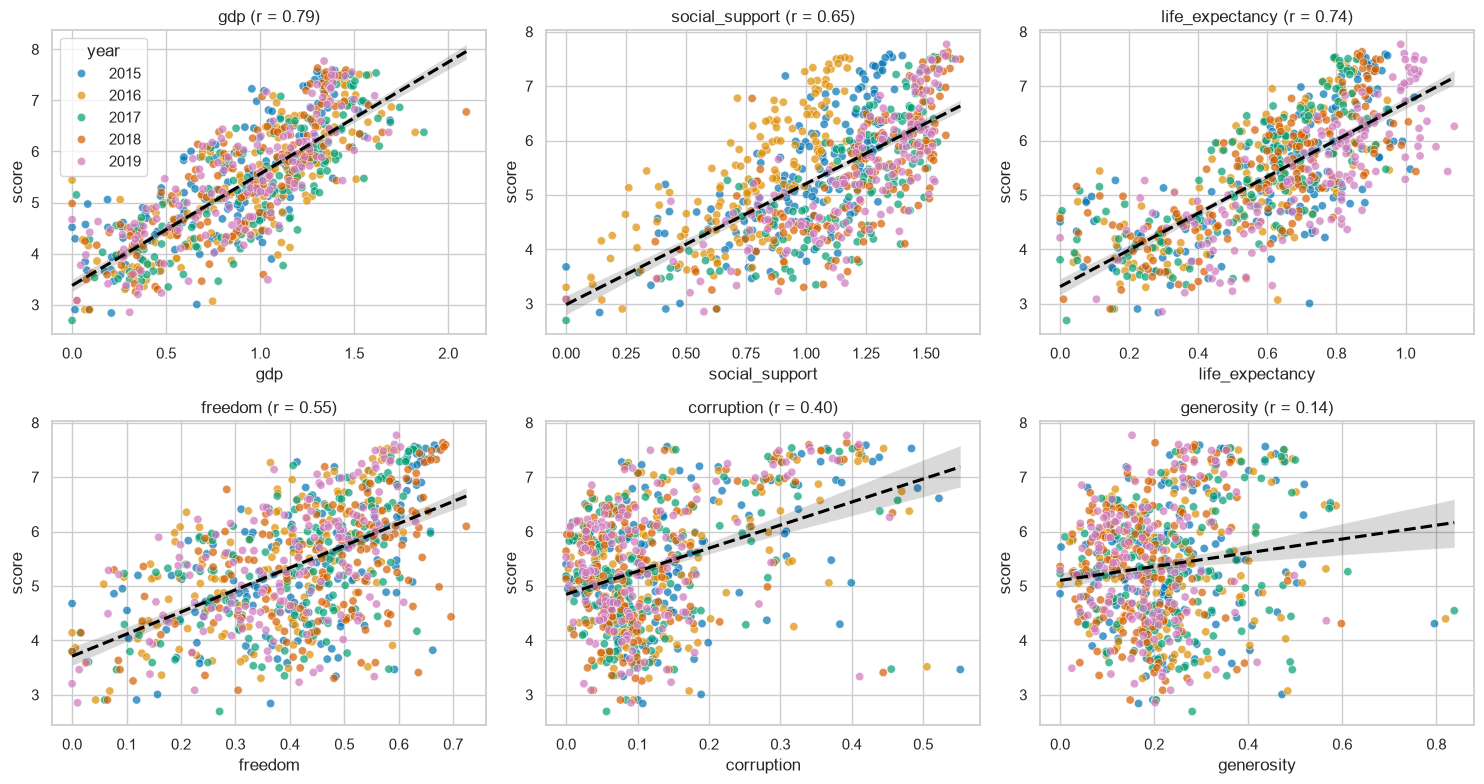

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.scatterplot(data=datos, x=col, y="score", hue="year", palette="colorblind",
                    alpha=0.7, ax=ax, legend=(col == FEATURES[0]))
    sns.regplot(data=datos.dropna(subset=[col]), x=col, y="score", scatter=False,
                color="black", line_kws={"linestyle": "--"}, ax=ax)
    ax.set_title(f"{col} (r = {datos[col].corr(datos['score']):.2f})")
plt.tight_layout()
plt.show()

## Selección de features

**Variable objetivo:** `score`. **Predictoras:** `gdp`, `social_support`, `life_expectancy`, `freedom`, `corruption`, `generosity`.

Criterios, a partir del EDA:

- Las seis variables existen con el mismo significado en los cinco años, y su relación con el score tiene el mismo signo (positivo) y una fuerza parecida en todas las ediciones.
- Correlación con el score: `gdp` 0.79, `life_expectancy` 0.74, `social_support` 0.65, `freedom` 0.55, `corruption` 0.40 y `generosity` 0.14. Esta última es débil, pero se conserva: al quitarla el R² de prueba baja ligeramente (de 0.774 a 0.767), así que no estorba.
- La única colinealidad fuerte entre predictoras es `gdp`–`life_expectancy` (0.78). No se elimina ninguna: con solo seis variables y una regresión lineal el efecto es manejable, aunque dificulta interpretar los coeficientes individuales.
- **`year` no se usa como feature.** Sube el R² apenas un punto (0.774 → 0.784), y un modelo que depende del año no sirve para registros de ediciones futuras, que quedarían fuera del rango de entrenamiento.
- Se descartan las columnas que ya se habían excluido en la integración (rank, error estándar, intervalos, `Dystopia Residual`, `Region`).

In [17]:
import sys
sys.path.append("../src")        # para importar transform.py desde src/
from transform import integrate, FEATURES as FEATURES_PIPELINE, TARGET

# Comprobación: la limpieza de transform.py (usada luego por predict.py) produce
# exactamente el mismo conjunto que se construyó paso a paso en este notebook.
registros = [{"record_id": r.record_id, "year": r.year, "data": json.loads(r.payload)}
             for r in raw.itertuples()]
chk = integrate(registros)
pd.testing.assert_frame_equal(chk[datos.columns].reset_index(drop=True),
                              datos.reset_index(drop=True), check_dtype=False)
assert FEATURES_PIPELINE == FEATURES
print("transform.py reproduce el mismo conjunto de datos:", chk.shape)

# Fuerza de la relación de cada variable con el score
print("\nCorrelación con el score:")
print(datos[FEATURES].corrwith(datos[TARGET]).sort_values(ascending=False).round(2).to_string())

transform.py reproduce el mismo conjunto de datos: (782, 10)

Correlación con el score:
gdp                0.79
life_expectancy    0.74
social_support     0.65
freedom            0.55
corruption         0.40
generosity         0.14


## Entrenamiento

**Separación train/test.** Cada país aparece hasta cinco veces (una por año). Con un split aleatorio simple, el mismo país quedaría en entrenamiento y en prueba, y el modelo "reconocería" países ya vistos: las métricas saldrían infladas. Por eso se usa `GroupShuffleSplit` agrupando por país (80 % / 20 %), y se verifica que no haya países compartidos.

**Preprocesamiento sin filtración.** La imputación por mediana (el nulo de `corruption` en UAE 2018) y el escalado se definen dentro de un `Pipeline`. Así, la mediana y la media/desviación se calculan únicamente con los datos de entrenamiento, y el conjunto de prueba solo se transforma con esos valores.

**Modelos.** *Linear Regression* como modelo base: es interpretable y las variables tienen una relación casi lineal con el score. Se compara con *Random Forest* para comprobar si una relación no lineal mejora el resultado. Ambos se evalúan antes con validación cruzada agrupada por país, solo dentro del conjunto de entrenamiento.

In [18]:
from sklearn.model_selection import GroupShuffleSplit

X = datos[FEATURES]
y = datos[TARGET]
paises = datos["country"]

# 80 % / 20 %, manteniendo todas las filas de un país en el mismo conjunto
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(gss.split(X, y, groups=paises))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print(f"Entrenamiento: {len(X_train)} filas | Prueba: {len(X_test)} filas")
print("Países compartidos entre train y test:",
      len(set(paises.iloc[idx_train]) & set(paises.iloc[idx_test])))
print("\nFilas de prueba por año:", datos.iloc[idx_test]["year"].value_counts().sort_index().to_dict())

Entrenamiento: 626 filas | Prueba: 156 filas
Países compartidos entre train y test: 0

Filas de prueba por año: {2015: 32, 2016: 32, 2017: 30, 2018: 30, 2019: 32}


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def make_pipeline(modelo):
    # La mediana y la media/desviación se calculan SOLO con los datos con que se hace fit
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", modelo),
    ])


modelos = {
    "Linear Regression": make_pipeline(LinearRegression()),
    "Random Forest": make_pipeline(
        RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)),
}

# Validación cruzada agrupada por país, solo sobre el conjunto de entrenamiento
grupos_train = paises.iloc[idx_train]
for nombre, pipe in modelos.items():
    cv = cross_val_score(pipe, X_train, y_train, groups=grupos_train,
                         cv=GroupKFold(n_splits=5), scoring="r2")
    print(f"{nombre:18s} R² en CV (5 folds): {cv.mean():.3f} ± {cv.std():.3f}")
    pipe.fit(X_train, y_train)

Linear Regression  R² en CV (5 folds): 0.718 ± 0.103
Random Forest      R² en CV (5 folds): 0.695 ± 0.062


## Evaluación

Se comparan las predicciones contra los valores reales del conjunto de prueba con MAE, MSE, RMSE, R² y R² ajustado. También se calculan sobre el entrenamiento para detectar sobreajuste.

In [20]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def metricas(y_real, y_pred, n_features):
    n = len(y_real)
    mse = mean_squared_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R²": r2, "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - n_features - 1)}


predicciones = {n: p.predict(X_test) for n, p in modelos.items()}
tabla = pd.DataFrame({n: metricas(y_test, pred, len(FEATURES))
                      for n, pred in predicciones.items()}).T
print("Conjunto de PRUEBA")
display(tabla.round(3))

# Comparación con entrenamiento para detectar sobreajuste
tabla_train = pd.DataFrame({n: metricas(y_train, p.predict(X_train), len(FEATURES))
                            for n, p in modelos.items()}).T
print("Conjunto de ENTRENAMIENTO")
display(tabla_train.round(3))
print(f"Desviación estándar del score en prueba: {y_test.std():.3f}")

Conjunto de PRUEBA


,MAE,MSE,RMSE,R²,R² ajustado
Linear Regression,0.450,0.348,0.59,0.774,0.765
Random Forest,0.489,0.397,0.63,0.742,0.732


Conjunto de ENTRENAMIENTO


,MAE,MSE,RMSE,R²,R² ajustado
Linear Regression,0.424,0.289,0.538,0.759,0.757
Random Forest,0.161,0.047,0.217,0.961,0.960


Desviación estándar del score en prueba: 1.245


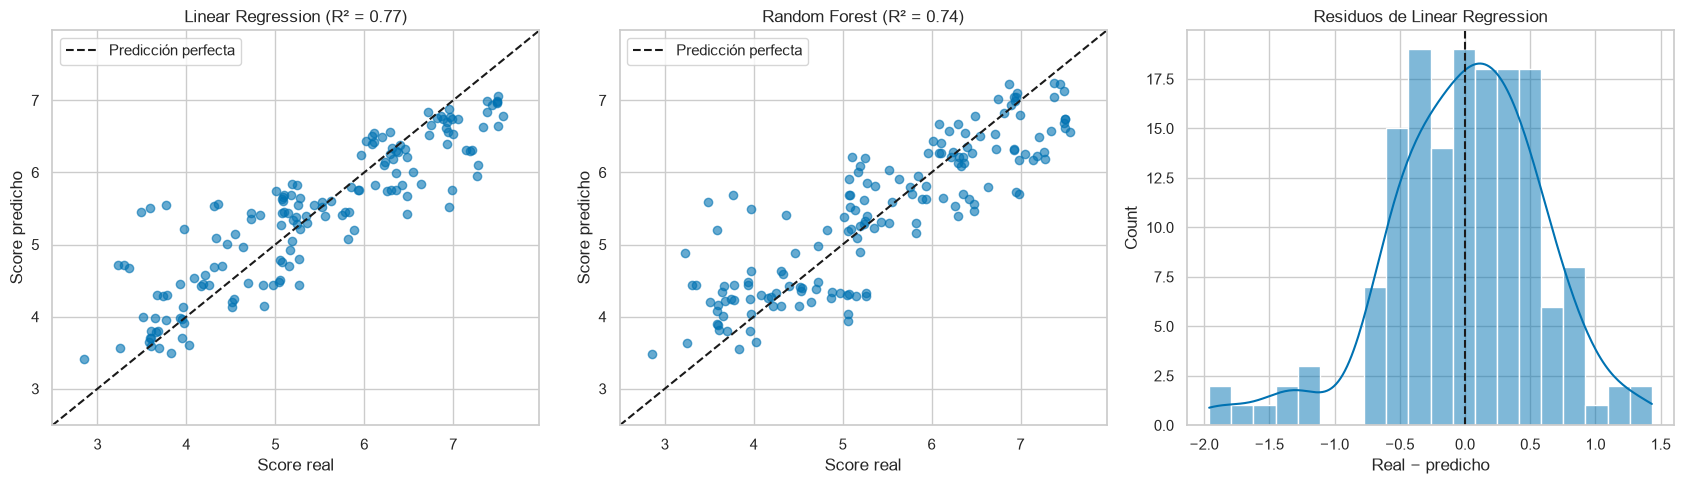

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
lim = [y.min() - 0.2, y.max() + 0.2]

for ax, (nombre, pred) in zip(axes[:2], predicciones.items()):
    ax.scatter(y_test, pred, alpha=0.6, color="#0072B2")
    ax.plot(lim, lim, "k--", label="Predicción perfecta")
    ax.set(xlim=lim, ylim=lim, xlabel="Score real", ylabel="Score predicho",
           title=f"{nombre} (R² = {r2_score(y_test, pred):.2f})")
    ax.legend()

residuos = y_test - predicciones["Linear Regression"]
sns.histplot(residuos, bins=20, kde=True, color="#0072B2", ax=axes[2])
axes[2].axvline(0, color="k", linestyle="--")
axes[2].set(title="Residuos de Linear Regression", xlabel="Real − predicho")
plt.tight_layout()
plt.show()

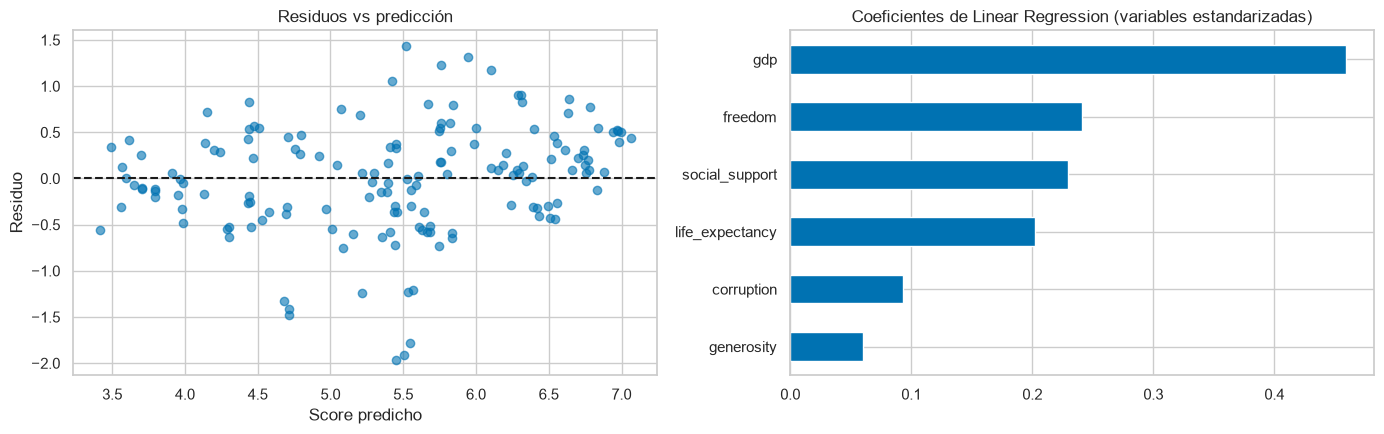

Coeficientes: {'gdp': 0.459, 'social_support': 0.229, 'life_expectancy': 0.202, 'freedom': 0.241, 'corruption': 0.093, 'generosity': 0.06}
Intercepto  : 5.369


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Residuos vs valor predicho: si hay patrón, el modelo omite algo
axes[0].scatter(predicciones["Linear Regression"], residuos, alpha=0.6, color="#0072B2")
axes[0].axhline(0, color="k", linestyle="--")
axes[0].set(xlabel="Score predicho", ylabel="Residuo", title="Residuos vs predicción")

# Coeficientes (variables estandarizadas, por eso son comparables entre sí)
coefs = pd.Series(modelos["Linear Regression"].named_steps["model"].coef_, index=FEATURES)
coefs.sort_values().plot.barh(color="#0072B2", ax=axes[1])
axes[1].set(title="Coeficientes de Linear Regression (variables estandarizadas)")
plt.tight_layout()
plt.show()

print("Coeficientes:", coefs.round(3).to_dict())
print("Intercepto  :", round(modelos["Linear Regression"].named_steps["model"].intercept_, 3))

In [23]:
resultado = datos.iloc[idx_test][["country", "year", TARGET]].copy()
resultado["predicho"] = predicciones["Linear Regression"]
resultado["error_abs"] = (resultado[TARGET] - resultado["predicho"]).abs()

print("Error absoluto medio por año (conjunto de prueba):")
print(resultado.groupby("year")["error_abs"].mean().round(3).to_dict())
print("\nLos 8 mayores errores:")
display(resultado.sort_values("error_abs", ascending=False).head(8).round(2))

Error absoluto medio por año (conjunto de prueba):
{2015: 0.411, 2016: 0.479, 2017: 0.438, 2018: 0.463, 2019: 0.46}

Los 8 mayores errores:


,country,year,score,predicho,error_abs
672,Botswana,2019,3.49,5.45,1.96
564,Botswana,2018,3.59,5.50,1.91
463,Botswana,2017,3.77,5.55,1.78
779,Tanzania,2019,3.23,4.71,1.48
207,Brazil,2016,6.95,5.52,1.43
624,Tanzania,2018,3.30,4.72,1.41
468,Tanzania,2017,3.35,4.68,1.33
267,Israel,2016,7.27,5.95,1.32


## Discusión de resultados y mejoras

**Resultados.** La regresión lineal explica cerca del 77 % de la varianza en países que no vio al entrenar (R² = 0.774, R² ajustado = 0.765). El error típico es de 0.45 puntos (MAE) y 0.59 (RMSE), frente a una desviación estándar del score de 1.25 en el conjunto de prueba. Es decir, el error es aproximadamente la mitad de la dispersión natural de los datos. El error es parecido en todos los años (entre 0.41 y 0.48), lo que sugiere que unificar las ediciones no introdujo un sesgo grande, a pesar de los cambios de nivel detectados en algunas variables.

**Modelos.** El Random Forest no mejora al lineal (R² = 0.742 en prueba, 0.695 en validación cruzada frente a 0.718 del lineal) y muestra sobreajuste claro: R² de 0.961 en entrenamiento contra 0.742 en prueba. La regresión lineal tiene R² similar en ambos conjuntos (0.759 y 0.774). Con solo ~600 filas y seis variables casi lineales, el modelo más simple generaliza igual o mejor, así que se elige como modelo final.

**Interpretación.** Con las variables estandarizadas, `gdp` es la de mayor peso (0.46), seguida de `freedom` (0.24), `social_support` (0.23) y `life_expectancy` (0.20); `corruption` (0.09) y `generosity` (0.06) aportan poco. El orden difiere un poco del de las correlaciones simples porque `gdp` y `life_expectancy` están correlacionadas entre sí y se reparten parte de la información.

**Dónde falla.** Los mayores errores se repiten por país: Botswana y Tanzania aparecen varias veces con scores reales mucho más bajos que lo predicho (error de 1.3 a 2.0 puntos), mientras que Brasil e Israel se subestiman. Como se separó por país, el modelo no puede aprender estas particularidades. Una hipótesis (no verificada) es que influyen factores no incluidos en las variables, como cultura o contexto regional.

**Posibles mejoras.**
- Recuperar una variable de región o continente (solo existe en 2015-2016, habría que reconstruirla desde otra fuente).
- Probar regularización (Ridge/Lasso) para manejar la colinealidad, y ajustar hiperparámetros del Random Forest o probar Gradient Boosting.
- Evaluar con validación cruzada agrupada completa en vez de un único split, porque el R² por fold varía bastante (desviación de 0.10).
- Verificar con documentación oficial si `Family` y `Social support` son realmente la misma variable (supuesto del notebook).
- Reentrenar con todos los datos antes de desplegar; aquí el modelo guardado usa solo el 80 % de entrenamiento para que las métricas reportadas correspondan exactamente al modelo.

## Guardado del modelo

El pipeline entrenado (imputación + escalado + regresión lineal) se guarda con `joblib`, junto con la lista de features y los países del conjunto de prueba. `predict.py` lo carga para predecir los registros que llegan de Kafka y cargarlos en la base de datos.

In [24]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump({"pipeline": modelos["Linear Regression"],
             "features": FEATURES,
             "test_countries": sorted(set(paises.iloc[idx_test]))},   # para marcar train/test al predecir
            "../models/happiness_model.joblib")
print("Modelo guardado en ../models/happiness_model.joblib")

Modelo guardado en ../models/happiness_model.joblib
